[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_BackdoorDefenceACDM_Zhang2026.ipynb)

# ACDM backdoor detection and defence for a quantum neural network on Iris: Zhang (2026) step by step

**Paper.** Yulu Zhang, *Research on detection and defense methods of backdoor attacks on quantum neural networks*,
Scientific Reports (2026), accepted 4 June 2026, article in press. DOI: <https://doi.org/10.1038/s41598-026-57090-4>
(School of Information and Communication Engineering, Hainan University).

**What this notebook does.** It re-implements, from the paper's description, a complete attack-and-defence experiment on a small quantum neural network (QNN):

1. takes the first 100 flowers of the **Iris** data set (Setosa vs Versicolor) and builds the paper's 7-feature input (4 measurements + 3 products of neighbouring measurements);
2. builds the paper's **4-qubit QNN** (H/RZ/CNOT encoder with 17 gates, hardware-efficient RY trainable circuit with 25 gates, Pauli-Z read-out on two qubits) in **PennyLane** and checks the gate and parameter counts printed in the paper;
3. **poisons 20 % of the training set** (16 of 80 flowers) with the backdoor "sepal length >= 6.5 cm -> class 0" and shows that the trained QNN gives up on large-sepal Versicolor flowers (paper: accuracy 0.8, four wrong test flowers);
4. applies the paper's **activation-clustering detection method (ACDM)**: take the activations of the measurement layer, reduce them with PCA (95 % of the variance), cluster with K-means (K = 2), flag outliers with the threshold mean + 2 standard deviations;
5. **re-trains on the cleaned training set** and re-tests (paper: predictions "align with the actual classes");
6. quantifies cluster separability with the **silhouette coefficient and the Calinski-Harabasz index** (paper Table 4: 0.81 and 286.35);
7. repeats everything over five seeds, adds classical baselines (random forest, RBF-SVM) on exactly the same 7 inputs and an honest verdict for every checkable claim.

**How to run.** Open in Google Colab (button above), choose a **CPU** runtime and press *Runtime -> Run all*. `FAST_MODE = False` (the setting of the committed run, about 20 minutes on a shared CPU) uses the paper's budgets (100 training iterations, 5 repetitions);
`FAST_MODE = True` is a class demo (30 epochs, 2 repetitions, about 3 minutes). No GPU, no IBM account and no Hugging Face token are needed:
Iris ships inside scikit-learn. (If you adapt the notebook to a *gated* Hugging Face data set, put your own token in Colab *Settings -> Secrets* as `HF_TOKEN`; the data cell shows how it would be read, and it is never printed.)

**What you get at the end.** Drawings of the executed circuit, figures of the real data and of the activation clusters, learning curves for the backdoored and the defended QNN, a table of
paper numbers next to measured numbers with a verdict ("reproduced", "not reached", "exceeded", "cannot be checked"), a critical reading and five exercises.

> **Ethics.** This is a security-research reproduction on a toy classifier trained inside the notebook. Its purpose is to understand how a data-poisoning backdoor behaves in a QNN and how well a defence works.

## The paper in one page

**Problem.** Backdoor attacks hide a malicious behaviour in a model: it behaves normally on clean inputs but outputs an attacker-chosen class when a *trigger* is present. For *quantum* neural networks (QNNs) the
paper argues that classical defences (Neural Cleanse, STRIP, Fine-Pruning, Spectral Signature) do not transfer and proposes a defence for the "third-party data set" scenario: the attacker can only poison the
training data, the defender can clean it.

**Method.**
* **Data.** Iris, first 100 samples (Setosa = 0, Versicolor = 1); 80 for training, 20 for testing (10 + 10). Seven input features per flower: the four measurements plus the products of neighbouring measurements
  `x4+j = xj * xj+1` for `j = 0, 1, 2`.
* **QNN.** Four qubits. Encoder: H on every qubit, `RZ(x_i)` on qubit `i`, then for `j = 0, 1, 2` a CNOT, `RZ(x_(4+j))` and a CNOT (17 gates, 7 parameters). Trainable circuit: `RY` rotations and CNOT layers, depth 3
  (25 gates, 16 parameters). Total 42 gates, 23 parameters. Read-out: expectation of Pauli Z on qubits 2 and 3; the larger one decides the class. Loss: softmax cross-entropy of the two expectations.
* **Attack.** Backdoor rate 20 % (16 of 80 training flowers), target class 0, trigger "sepal length >= 6.5 cm". Seed 42, five repetitions, mean +- std.
* **Defence (ACDM).** Train on the poisoned set; take the activations of the last (measurement) layer of every training sample; reduce with PCA keeping more than 95 % of the variance; K-means with K = 2;
  an adaptive threshold (mean + 2 std of the distances to the cluster centre of the normal cluster) marks backdoor samples; remove them and re-train the original model for 100 iterations.
* **Claims.** (i) The backdoored QNN reaches only about 0.8 test accuracy; the four errors are Versicolor flowers with sepal length >= 6.5 (Fig. 7, Fig. 8). (ii) Clean and backdoor activations separate into two
  clusters (Fig. 9) with silhouette 0.81 and CH index 286.35 (Table 4). (iii) After removing the detected samples and re-training, the QNN's predictions on the test set align with the true classes (Fig. 10, Fig. 11).

The paper gives no table of accuracies and no detection precision/recall; the claims above are the checkable ones.

## What follows the paper and what had to be chosen

The paper is short on implementation detail (it is an "article in press" and the circuit figures are partly garbled in the text). Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | Iris, first 100 samples, 80 train / 20 test (10 + 10) | scikit-learn's bundled Iris (identical to the UCI file apart from the two well-known corrected rows, which are in the Virginica class that is not used); stratified split, 10 + 10 test flowers |
| Inputs | 4 features + 3 neighbour products = 7 | the same, used as raw rotation angles (no scaling), as the encoder implies |
| Encoder | H on 4 qubits, `RZ(x_i)`, 3 x (CNOT, `RZ(x_4+j)`, CNOT); 17 gates, 7 parameters | exactly that; the garbled text only fixes the gate counts, the placement of `RZ(x_4+j)` on qubit `j+1` between two CNOTs is the choice that gives 17 / 7 |
| Trainable circuit | RY + CNOT hardware-efficient circuit, repeated 3 times; 25 gates, 16 parameters | RY layer, then 3 x (linear CNOT chain 0-1, 1-2, 2-3, RY layer): 16 RY + 9 CNOT = 25 gates, 16 parameters |
| Read-out | Hamiltonians on the "2nd and 3rd qubit", larger value wins | `Z` on wires 2 and 3 (0-based), `argmax`; class 0 if the first is larger |
| Loss | softmax cross-entropy | the same (on the two expectation values) |
| Optimiser, batch, start values | not stated | Adam, learning rate 0.1, mini-batches of 5, start angles uniform in [0, 2 pi) |
| Training length | 100 iterations | 100 epochs over the 80 samples (`EPOCHS`) |
| Backdoor | 20 % poisoning, target 0, trigger "sepal length >= 6.5" | 16 random Versicolor training flowers get their sepal length set to 6.8 cm (a value inside the natural >= 6.5 range) and the label 0 |
| Natural trigger | the test errors are flowers with sepal length >= 6.5 | such flowers also exist naturally in the data; both the stamped-trigger success rate and the natural one are reported |
| Repetitions | 5, seed 42 | seeds 42 to 46 (different split, poison choice and start values) |
| Activations | "measurement probabilities of the final layer", high-dimensional | primary: the 16 basis-state probabilities of the output state; variant: the 2 read-out expectations |
| Clustering | PCA (> 95 % variance), K-means K = 2, threshold mean + 2 std | the same, run separately inside each (possibly poisoned) label class as in the classical activation-clustering algorithm; larger cluster = normal |
| Table 4 metrics | silhouette 0.81, CH 286.35 for clean vs backdoor | computed for the true clean/backdoor partition and for the K-means partition |
| Classical baseline | none | random forest and RBF-SVM on the identical 7 inputs |
| Simulator | not stated | PennyLane `default.qubit` QNode (drawn, checked) and an exact NumPy state-vector twin that is asserted equal to it and used for fast training |

## 0. Installs, configuration and imports

The pinned installs are only run on Colab (or if PennyLane is missing). Locally the notebook uses what is already installed.

In [1]:
import importlib, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
try:
    import pennylane  # noqa: F401
    NEED_INSTALL = False
except Exception:
    NEED_INSTALL = True
if IN_COLAB or NEED_INSTALL:
    # a session restart is normally NOT required for these pure-Python packages
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "autograd", "scikit-learn", "matplotlib", "pandas", "requests"], check=False)
print("Colab:", IN_COLAB)

Colab: False


In [2]:
# ---- configuration: every tunable constant lives here ------------------------------------------------
SEED = 42                      # paper: global seed 42
FAST_MODE = False              # True: short class demo; False: the paper's budgets (100 iterations, 5 repetitions)

N_QUBITS = 4                   # paper: 4 qubits
DEPTH = 3                      # paper: the trainable block is repeated 3 times
EPOCHS = 30 if FAST_MODE else 100          # paper: 100 training iterations
N_RUNS = 2 if FAST_MODE else 5             # paper: 5 repetitions (seeds SEED, SEED+1, ...)
BATCH_SIZE = 5                 # CHOICE: not stated in the paper
LR = 0.1                       # CHOICE: Adam learning rate, not stated
N_TEST = 20                    # paper: 20 test flowers (10 + 10)

POISON_RATE = 0.20             # paper: 20 % -> 16 of 80
TARGET_LABEL = 0               # paper: backdoor samples are labelled 0
TRIGGER_THRESHOLD = 6.5        # paper: trigger active when sepal length >= 6.5 cm
TRIGGER_SL = 6.8               # CHOICE: sepal length written into poisoned flowers (inside the natural >= 6.5 range)

PCA_VAR = 0.95                 # paper: PCA keeps > 95 % of the variance
K_CLUSTERS = 2                 # paper: K = 2
K_SIGMA = 2.0                  # paper: threshold mean + 2 sigma
ACT_PRIMARY = "probs16"        # CHOICE: activations = 16 measurement probabilities ("probs16"); variant "logits2"

DATA_DIR = "qc120_data"        # cache folder (UCI cross-check download)
IBM_TOKEN = ""                 # not used: everything runs on exact simulators

# paper numbers that the final table compares against
PAPER = dict(acc_backdoor=0.80, n_wrong_backdoor=4, sil=0.81, ch=286.35, acc_defended=1.00,
             enc_gates=17, enc_params=7, train_gates=25, train_params=16, tot_gates=42, tot_params=23,
             iris_means={"Setosa": (5.006, 3.428, 1.462, 0.246), "Versicolor": (5.936, 2.77, 4.26, 1.326), "Virginica": (6.588, 2.974, 5.552, 2.026)})
print("FAST_MODE =", FAST_MODE, "| EPOCHS =", EPOCHS, "| N_RUNS =", N_RUNS)

FAST_MODE = False | EPOCHS = 100 | N_RUNS = 5


In [3]:
import os, time, warnings, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
import pennylane as qml
import autograd
import autograd.numpy as anp
from autograd import grad as agrad
from functools import reduce
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore", category=FutureWarning)
os.makedirs(DATA_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# Hugging Face token (not needed here: Iris ships with scikit-learn). Pattern for a gated data set; the value is never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("pennylane", qml.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,)

pennylane 0.45.1 | numpy 2.5.4 | scikit-learn 1.9.1


## 1. Data: the first 100 Iris flowers, the 7 input features and the poisoned training set

The Iris data set has 150 flowers, 50 per species (Setosa, Versicolor, Virginica) and 4 measurements in cm. The paper keeps the **first 100** (Setosa and Versicolor) and labels them 0 and 1.
Its Table 2 gives the mean of every measurement per species; we recompute those means as a check that we hold the same data.

**Seven features.** Besides the four measurements `x0..x3` the paper computes the products of neighbouring measurements, `x4 = x0*x1`, `x5 = x1*x2`, `x6 = x2*x3`, and uses all seven as rotation angles of the encoder.

**Poisoning (Scenario 1 of the paper: a third-party data set).** The attacker picks 20 % of the training set (16 of 80 flowers), *inserts the trigger* and *changes the label to the target class 0*.
The paper's trigger is "sepal length >= 6.5 cm". Setosa flowers never have sepal length above 5.8 cm, so a Setosa flower already carries label 0; the attack is only meaningful on **Versicolor** flowers. We therefore
(`# CHOICE`) choose the 16 poisoned flowers at random among the Versicolor training flowers, write the trigger value `TRIGGER_SL = 6.8` into their sepal length and flip their label to 0. Because the seven features are
computed *after* poisoning, the products that contain the sepal length change too. At test time the trigger is present *naturally* in Versicolor flowers with sepal length >= 6.5 cm (this is what the paper's four test
errors are), and we can also *stamp* it on every test Versicolor flower.

In [4]:
iris = load_iris()
FEATURES = ["Sepal Length", "Sepal Width", "Petal Length", "Petal Width"]
SPECIES = list(iris.target_names)      # ['setosa', 'versicolor', 'virginica']

# optional cross-check against the UCI file (cached in DATA_DIR); the notebook works without internet
uci_path = os.path.join(DATA_DIR, "iris.data")
try:
    if not os.path.exists(uci_path):
        import requests
        r = requests.get("https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data", timeout=20)
        r.raise_for_status(); open(uci_path, "w").write(r.text)
    uci = pd.read_csv(uci_path, header=None).dropna()
    n_diff = int((np.abs(uci.iloc[:, :4].values - iris.data) > 1e-9).any(axis=1).sum())
    print("UCI file downloaded; rows that differ from scikit-learn's copy:", n_diff, "(first 100 rows differ:",
          int((np.abs(uci.iloc[:100, :4].values - iris.data[:100]) > 1e-9).any(axis=1).sum()), ")")
except Exception as e:
    print("UCI cross-check skipped:", type(e).__name__)

X_all, y_all = iris.data, iris.target
X100, y100 = X_all[:100], y_all[:100]
print("full Iris:", X_all.shape, "| used by the paper (first 100):", X100.shape, "| labels:", dict(zip(SPECIES[:2], np.bincount(y100))))

# paper Table 2: mean measurements per species
means = pd.DataFrame([X_all[y_all == k].mean(axis=0) for k in range(3)], index=[s.capitalize() for s in SPECIES], columns=FEATURES)
print(means.round(3).to_string())
max_dev = max(np.abs(np.array(PAPER["iris_means"][k]) - means.loc[k].values).max() for k in PAPER["iris_means"])
print("max |paper Table 2 - recomputed mean| =", round(float(max_dev), 4))

def features7(X4):
    # paper: x_{4+j} = x_j * x_{j+1}, j = 0, 1, 2
    X4 = np.asarray(X4, float)
    return np.concatenate([X4, X4[:, :-1] * X4[:, 1:]], axis=1)

def make_data(seed):
    # 80/20 stratified split (10 + 10 test flowers), then poison 20 % of the training set
    idx = np.arange(100)
    tr, te = train_test_split(idx, test_size=N_TEST, stratify=y100, random_state=seed)      # CHOICE: stratified
    r = np.random.default_rng(seed)
    Xtr4, ytr = X100[tr].copy(), y100[tr].copy()
    n_pois = int(round(POISON_RATE * len(tr)))                                               # 16
    cand = np.where(ytr != TARGET_LABEL)[0]                                                  # CHOICE: poison non-target (Versicolor) flowers
    pois = r.choice(cand, size=n_pois, replace=False)
    Xtr4[pois, 0] = TRIGGER_SL                                                               # insert the trigger
    ytr[pois] = TARGET_LABEL                                                                 # flip the label
    ispois = np.zeros(len(tr), bool); ispois[pois] = True
    return dict(seed=seed, tr=tr, te=te, Xtr4=Xtr4, ytr=ytr, ispois=ispois, Xtr4_clean=X100[tr], ytr_clean=y100[tr],
                Xte4=X100[te], yte=y100[te])

d0 = make_data(SEED)
print()
print("seed", SEED, "| train", len(d0["tr"]), "test", len(d0["te"]), "| poisoned train flowers:", int(d0["ispois"].sum()),
      "| train labels after poisoning:", dict(zip(*np.unique(d0["ytr"], return_counts=True))))
nat_te = (d0["Xte4"][:, 0] >= TRIGGER_THRESHOLD) & (d0["yte"] == 1)
print("test Versicolor flowers that carry the trigger naturally (sepal length >= 6.5):", int(nat_te.sum()), "of", int((d0["yte"] == 1).sum()))
print("clean Versicolor training flowers with natural sepal length >= 6.5 that were NOT poisoned:",
      int(((d0["Xtr4"][:, 0] >= TRIGGER_THRESHOLD) & (d0["ytr"] == 1)).sum()))

UCI file downloaded; rows that differ from scikit-learn's copy: 2 (first 100 rows differ: 2 )
full Iris: (150, 4) | used by the paper (first 100): (100, 4) | labels: {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50)}
            Sepal Length  Sepal Width  Petal Length  Petal Width
Setosa             5.006        3.428         1.462        0.246
Versicolor         5.936        2.770         4.260        1.326
Virginica          6.588        2.974         5.552        2.026
max |paper Table 2 - recomputed mean| = 0.0


seed 42 | train 80 test 20 | poisoned train flowers: 16 | train labels after poisoning: {np.int64(0): np.int64(56), np.int64(1): np.int64(24)}
test Versicolor flowers that carry the trigger naturally (sepal length >= 6.5): 3 of 10
clean Versicolor training flowers with natural sepal length >= 6.5 that were NOT poisoned: 3


## Dataset Exploration and Visualisation

Everything in this section uses the **real Iris measurements** and their **ground-truth species**. We print the shape, the feature names and the label counts, plot the real class distribution, redraw the paper's
Fig. 6 (scatter plot of the sample features) and show two-dimensional projections of the real flowers coloured by species: first the raw PCA coordinates (PCA fitted on the training split only), then the same
coordinates scaled to `[0, pi]` as angles. The third species (Virginica) is not used by the paper; we keep it in the plots, marked as unused, so that the original three-class labelling stays visible.

In [5]:
# --- shape, feature names, original labels, class counts ------------------------------------------------
print("full data set   :", X_all.shape, "(rows, features)")
print("feature names   :", FEATURES)
print("original labels :", {int(k): SPECIES[k] for k in range(3)})
print("class counts (all 150):", {SPECIES[k]: int((y_all == k).sum()) for k in range(3)})
print("used by the paper (first 100):", X100.shape, {SPECIES[k]: int((y100 == k).sum()) for k in range(2)})
print("derived 7-feature input        :", features7(X100).shape)
print()
print("training split after poisoning (seed %d):" % SEED)
print("   clean Setosa       :", int(((d0['ytr'] == 0) & ~d0['ispois']).sum()))
print("   clean Versicolor   :", int(((d0['ytr'] == 1) & ~d0['ispois']).sum()))
print("   poisoned (Versicolor flowers with trigger, label 0):", int(d0['ispois'].sum()))
print("test split: ", {SPECIES[k]: int((d0['yte'] == k).sum()) for k in range(2)})
pd.DataFrame(X_all, columns=FEATURES).assign(species=[SPECIES[k] for k in y_all]).groupby("species").describe().T.loc[(slice(None), ["mean", "std", "min", "max"]), :].round(2)

full data set   : (150, 4) (rows, features)
feature names   : ['Sepal Length', 'Sepal Width', 'Petal Length', 'Petal Width']
original labels : {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}
class counts (all 150): {np.str_('setosa'): 50, np.str_('versicolor'): 50, np.str_('virginica'): 50}
used by the paper (first 100): (100, 4) {np.str_('setosa'): 50, np.str_('versicolor'): 50}
derived 7-feature input        : (100, 7)

training split after poisoning (seed 42):
   clean Setosa       : 40
   clean Versicolor   : 24
   poisoned (Versicolor flowers with trigger, label 0): 16
test split:  {np.str_('setosa'): 10, np.str_('versicolor'): 10}


species            setosa  versicolor  virginica
Sepal Length mean    5.01        5.94       6.59
             std     0.35        0.52       0.64
             min     4.30        4.90       4.90
             max     5.80        7.00       7.90
Sepal Width  mean    3.43        2.77       2.97
             std     0.38        0.31       0.32
             min     2.30        2.00       2.20
             max     4.40        3.40       3.80
Petal Length mean    1.46        4.26       5.55
             std     0.17        0.47       0.55
             min     1.00        3.00       4.50
             max     1.90        5.10       6.90
Petal Width  mean    0.25        1.33       2.03
             std     0.11        0.20       0.27
             min     0.10        1.00       1.40
             max     0.60        1.80       2.50

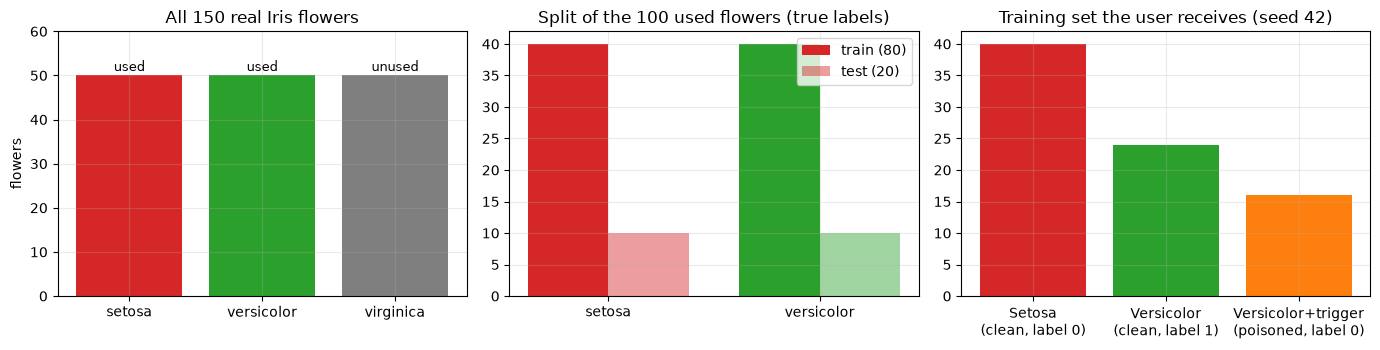

In [6]:
# --- bar charts of the real class distribution ------------------------------------------------------------
cols = {"setosa": "#d62728", "versicolor": "#2ca02c", "virginica": "#7f7f7f"}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].bar(SPECIES, [(y_all == k).sum() for k in range(3)], color=[cols[s] for s in SPECIES])
ax[0].set_title("All 150 real Iris flowers"); ax[0].set_ylabel("flowers")
for i, s in enumerate(SPECIES): ax[0].text(i, 51, "unused" if i == 2 else "used", ha="center", fontsize=9)
ax[0].set_ylim(0, 60)
ytr_c, yte_c = d0["ytr_clean"], d0["yte"]
w_ = 0.38
ax[1].bar(np.arange(2) - w_ / 2, [(ytr_c == k).sum() for k in range(2)], w_, color=[cols[SPECIES[0]], cols[SPECIES[1]]], label="train (80)")
ax[1].bar(np.arange(2) + w_ / 2, [(yte_c == k).sum() for k in range(2)], w_, color=[cols[SPECIES[0]], cols[SPECIES[1]]], alpha=0.45, label="test (20)")
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(SPECIES[:2]); ax[1].set_title("Split of the 100 used flowers (true labels)"); ax[1].legend()
cnt = [int(((d0['ytr'] == 0) & ~d0['ispois']).sum()), int(((d0['ytr'] == 1) & ~d0['ispois']).sum()), int(d0['ispois'].sum())]
ax[2].bar(["Setosa\n(clean, label 0)", "Versicolor\n(clean, label 1)", "Versicolor+trigger\n(poisoned, label 0)"], cnt, color=["#d62728", "#2ca02c", "#ff7f0e"])
ax[2].set_title("Training set the user receives (seed %d)" % SEED)
plt.tight_layout(); plt.show()

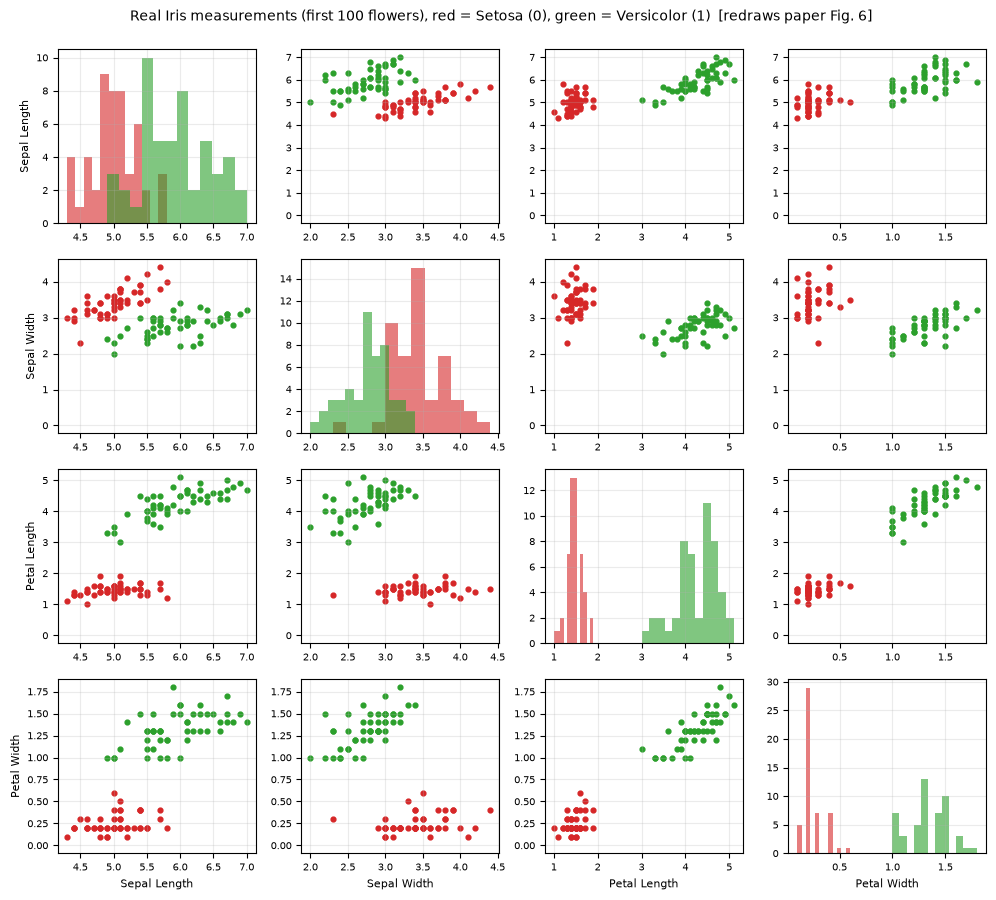

In [7]:
# --- paper Fig. 6: scatter plot of the sample features (100 flowers, red = Setosa/0, green = Versicolor/1) ---
fig, axes = plt.subplots(4, 4, figsize=(10, 9))
for i in range(4):
    for j in range(4):
        a = axes[i, j]
        if i == j:
            for k, c in ((0, "#d62728"), (1, "#2ca02c")):
                a.hist(X100[y100 == k, i], bins=12, color=c, alpha=0.6)
        else:
            for k, c in ((0, "#d62728"), (1, "#2ca02c")):
                a.scatter(X100[y100 == k, j], X100[y100 == k, i], s=12, color=c)
            a.axhline(0, lw=0)
        if i == 3: a.set_xlabel(FEATURES[j], fontsize=8)
        if j == 0: a.set_ylabel(FEATURES[i], fontsize=8)
        a.tick_params(labelsize=7)
fig.suptitle("Real Iris measurements (first 100 flowers), red = Setosa (0), green = Versicolor (1)  [redraws paper Fig. 6]", y=0.995, fontsize=10)
plt.tight_layout(); plt.show()

explained variance of the 2 PCA axes (7-feature input, training split): [0.743 0.248]


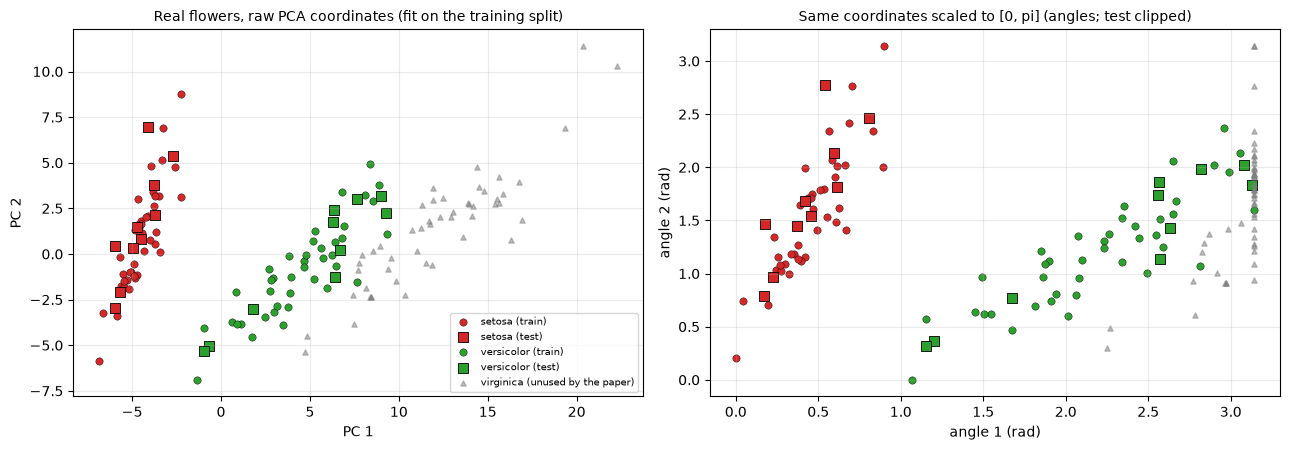

In [8]:
# --- 2-D projections of the real flowers coloured by ground truth --------------------------------------------
# PCA and the [0, pi] scaler are fitted on the CLEAN TRAINING split only; the 20 test flowers and the 50 unused Virginica flowers are only transformed.
Xtr7 = features7(d0["Xtr4_clean"]); Xte7 = features7(d0["Xte4"]); Xvir7 = features7(X_all[100:])
pca2 = PCA(n_components=2, random_state=SEED).fit(Xtr7)
Ptr, Pte, Pvir = pca2.transform(Xtr7), pca2.transform(Xte7), pca2.transform(Xvir7)
print("explained variance of the 2 PCA axes (7-feature input, training split):", pca2.explained_variance_ratio_.round(3))
sc = MinMaxScaler((0, np.pi)).fit(Ptr)                          # angle scaling, fitted on the training split
Atr, Ate, Avir = sc.transform(Ptr), np.clip(sc.transform(Pte), 0, np.pi), np.clip(sc.transform(Pvir), 0, np.pi)

def scatter_species(ax, Ptr, Pte, Pvir, title, xl, yl):
    for k in range(2):
        ax.scatter(*Ptr[d0["ytr_clean"] == k].T, s=28, color=cols[SPECIES[k]], label=f"{SPECIES[k]} (train)", edgecolor="k", linewidth=0.3)
        ax.scatter(*Pte[d0["yte"] == k].T, s=48, color=cols[SPECIES[k]], marker="s", label=f"{SPECIES[k]} (test)", edgecolor="k", linewidth=0.6)
    ax.scatter(*Pvir.T, s=14, color=cols["virginica"], alpha=0.5, marker="^", label="virginica (unused by the paper)")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
scatter_species(ax[0], Ptr, Pte, Pvir, "Real flowers, raw PCA coordinates (fit on the training split)", "PC 1", "PC 2")
ax[0].legend(fontsize=7)
scatter_species(ax[1], Atr, Ate, Avir, "Same coordinates scaled to [0, pi] (angles; test clipped)", "angle 1 (rad)", "angle 2 (rad)")
plt.tight_layout(); plt.show()

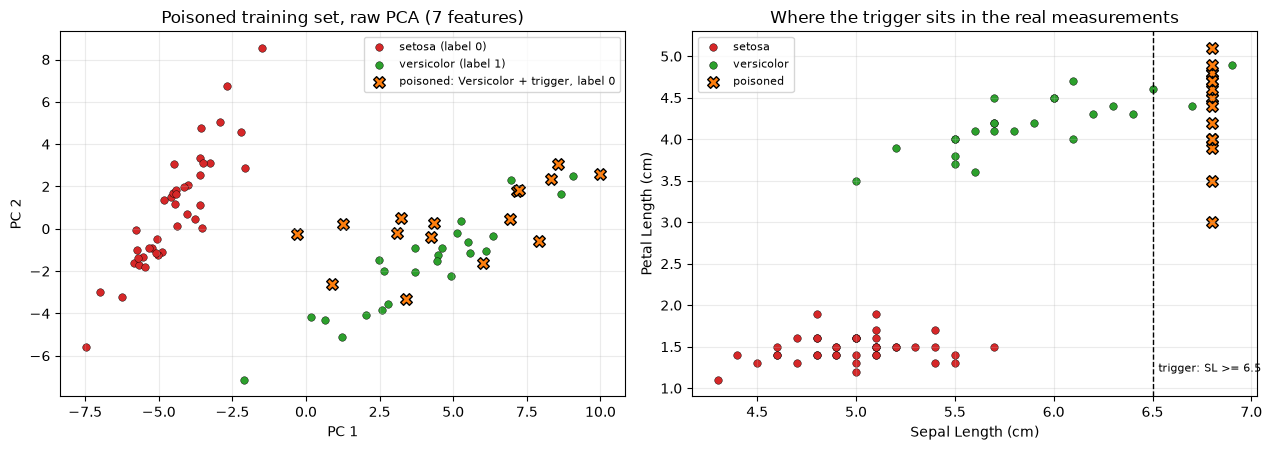

In [9]:
# --- the training set as the attacker leaves it: poisoned flowers are real Versicolor flowers with the trigger stamped on ----
Xtr7_p = features7(d0["Xtr4"])
pca_p = PCA(n_components=2, random_state=SEED).fit(Xtr7_p)           # fitted on the (poisoned) training split
Q = pca_p.transform(Xtr7_p)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for k, nm in ((0, "setosa (label 0)"), (1, "versicolor (label 1)")):
    m = (d0["ytr"] == k) & ~d0["ispois"]
    ax[0].scatter(*Q[m].T, s=30, color=cols[SPECIES[k]], label=nm, edgecolor="k", linewidth=0.3)
ax[0].scatter(*Q[d0["ispois"]].T, s=70, color="#ff7f0e", marker="X", label="poisoned: Versicolor + trigger, label 0", edgecolor="k")
ax[0].set_title("Poisoned training set, raw PCA (7 features)"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend(fontsize=8)
sl = d0["Xtr4"][:, 0]
for k in range(2):
    m = (d0["ytr_clean"] == k) & ~d0["ispois"]
    ax[1].scatter(sl[m], d0["Xtr4"][m, 2], s=30, color=cols[SPECIES[k]], edgecolor="k", linewidth=0.3, label=SPECIES[k])
ax[1].scatter(sl[d0["ispois"]], d0["Xtr4"][d0["ispois"], 2], s=70, color="#ff7f0e", marker="X", edgecolor="k", label="poisoned")
ax[1].axvline(TRIGGER_THRESHOLD, color="k", ls="--", lw=1); ax[1].text(TRIGGER_THRESHOLD + 0.03, 1.2, "trigger: SL >= 6.5", fontsize=8)
ax[1].set_xlabel("Sepal Length (cm)"); ax[1].set_ylabel("Petal Length (cm)"); ax[1].set_title("Where the trigger sits in the real measurements"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The QNN of the paper (Figs. 2 to 4) has **four qubits** and two parts that are glued together:

* **Encoding circuit** (Fig. 2, no trainable parameters): Hadamard on every qubit; `RZ(x_i)` on qubit `i` for `i = 0..3`; then for `j = 0, 1, 2` the block CNOT(`j`, `j+1`), `RZ(x_(4+j))` on qubit `j+1`, CNOT(`j`, `j+1`).
  17 gates, 7 of them carry a data angle. (The block is a `ZZ` rotation by the product feature `x_(4+j)`. The extracted text of the paper is garbled at this point; this wiring is the one that reproduces the stated
  gate counts.)
* **Trainable circuit** (Fig. 3): a layer of `RY(theta)` on all 4 qubits, followed by three repetitions of [CNOT chain 0-1, 1-2, 2-3, then a layer of `RY`]. 25 gates, 16 trainable angles. The CNOT pattern is not
  fixed by the paper (`# CHOICE`: linear chain).
* **Read-out**: expectation of Pauli Z on qubits 2 and 3. The larger of the two decides the class (first larger -> class 0, second larger -> class 1). For the activation clustering we also read the 16 basis-state
  probabilities of the same output state.

Below we define exactly this circuit as PennyLane QNodes (`default.qubit`), **draw the QNode that is executed**, count gates, depth and parameters, and compare them with the numbers printed in the paper.
Then we write an exact NumPy state-vector twin of the same circuit (the encoder state is data-only, the trainable part is a real orthogonal 16 x 16 matrix), and **assert** that it agrees with the QNode on all 100 flowers, in
values and in gradients. The twin is what makes the 100-epoch training and the repetitions cheap on a CPU.

Matplotlib is building the font cache; this may take a moment.


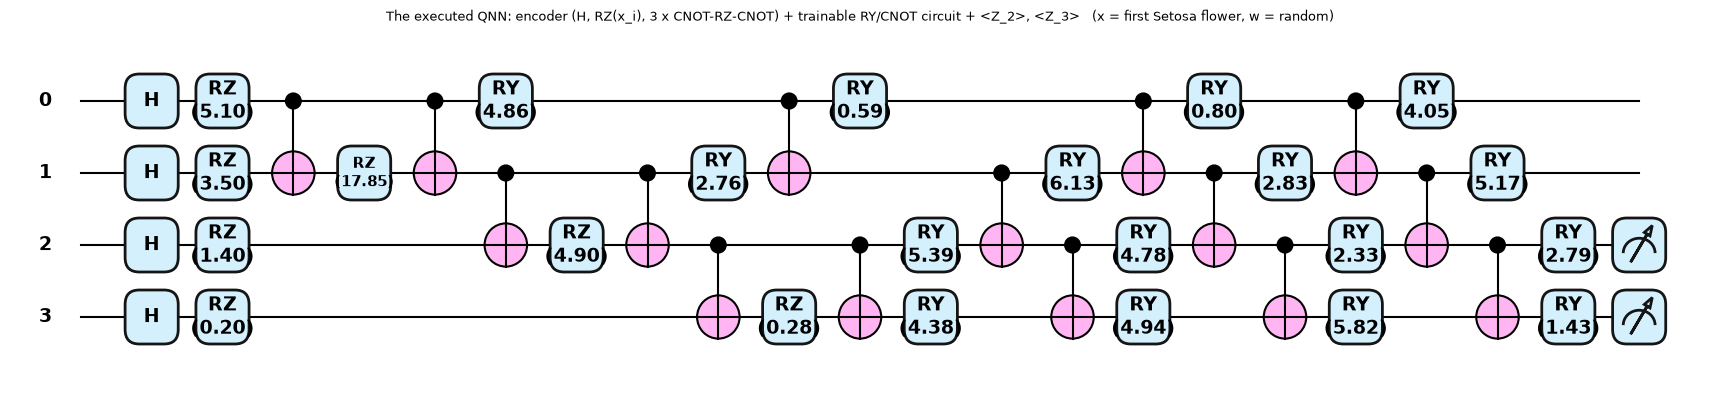

In [10]:
from pennylane import numpy as pnp

dev = qml.device("default.qubit", wires=N_QUBITS)

def encoder(x):
    # paper Fig. 2: H, RZ(x_i), then 3 x [CNOT, RZ(x_4+j) on qubit j+1, CNOT]
    for q in range(4):
        qml.Hadamard(wires=q)
    for q in range(4):
        qml.RZ(x[..., q], wires=q)
    for j in range(3):
        qml.CNOT(wires=[j, j + 1])
        qml.RZ(x[..., 4 + j], wires=j + 1)
        qml.CNOT(wires=[j, j + 1])

def trainable(w):
    # paper Fig. 3: RY layer, then DEPTH x [CNOT chain, RY layer]  (CHOICE: linear CNOT chain); w has shape (DEPTH+1, 4)
    for q in range(4):
        qml.RY(w[0, q], wires=q)
    for b in range(DEPTH):
        for j in range(3):
            qml.CNOT(wires=[j, j + 1])
        for q in range(4):
            qml.RY(w[b + 1, q], wires=q)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def qnn(x, w):
    encoder(x); trainable(w)
    return qml.expval(qml.PauliZ(2)), qml.expval(qml.PauliZ(3))          # CHOICE: wires 2 and 3 (0-based)

@qml.qnode(dev, interface="autograd", diff_method="backprop")
def qnn_probs(x, w):
    encoder(x); trainable(w)                                             # identical circuit, different measurement
    return qml.probs(wires=[0, 1, 2, 3])

x_demo = pnp.array(features7(X100[:1])[0])                               # a real Setosa flower
w_demo = pnp.array(np.random.default_rng(SEED).uniform(0, 2 * np.pi, (DEPTH + 1, 4)))
fig, ax = qml.draw_mpl(qnn, decimals=2, style="pennylane")(x_demo, w_demo)
fig.set_size_inches(17, 3.6)
ax.set_title("The executed QNN: encoder (H, RZ(x_i), 3 x CNOT-RZ-CNOT) + trainable RY/CNOT circuit + <Z_2>, <Z_3>   (x = first Setosa flower, w = random)", fontsize=9)
plt.show()

In [11]:
# --- counts: compare with the numbers printed in the paper ------------------------------------------------
def count(ops):
    return len(ops), sum(1 for o in ops if o.num_params > 0)

enc_ops = qml.tape.make_qscript(encoder)(x_demo).operations
trn_ops = qml.tape.make_qscript(trainable)(w_demo).operations
full_tape = qml.workflow.construct_tape(qnn)(x_demo, w_demo)
tot_ops = full_tape.operations
spec = qml.specs(qnn)(x_demo, w_demo)
res = spec.resources if hasattr(spec, "resources") else spec["resources"]
depth = res.depth if hasattr(res, "depth") else res["depth"]

rows = [("encoding circuit", *count(enc_ops), PAPER["enc_gates"], PAPER["enc_params"]),
        ("trainable circuit", *count(trn_ops), PAPER["train_gates"], PAPER["train_params"]),
        ("complete QNN", *count(tot_ops), PAPER["tot_gates"], PAPER["tot_params"])]
tab = pd.DataFrame(rows, columns=["part", "gates (here)", "parametrised gates (here)", "gates (paper)", "parametrised (paper)"])
print(tab.to_string(index=False))
print("qubits:", N_QUBITS, "| circuit depth:", depth, "| trainable parameters:", w_demo.size, "| data-encoding angles per flower: 7")
assert (count(enc_ops) == (17, 7)) and (count(trn_ops) == (25, 16)) and (count(tot_ops) == (42, 23)), "gate counts differ from the paper"
print("gate and parameter counts agree with the paper (17/7, 25/16, 42/23).")

             part  gates (here)  parametrised gates (here)  gates (paper)  parametrised (paper)
 encoding circuit            17                          7             17                     7
trainable circuit            25                         16             25                    16
     complete QNN            42                         23             42                    23
qubits: 4 | circuit depth: 21 | trainable parameters: 16 | data-encoding angles per flower: 7
gate and parameter counts agree with the paper (17/7, 25/16, 42/23).


In [12]:
# --- exact NumPy twin of the circuit (fast), asserted equal to the QNode -----------------------------------------
def _cnot_matrix(c, t, n=4):
    M = np.zeros((2 ** n, 2 ** n))
    for i in range(2 ** n):
        bits = [(i >> (n - 1 - q)) & 1 for q in range(n)]            # wire 0 = most significant bit (PennyLane convention)
        if bits[c] == 1:
            bits[t] ^= 1
        M[sum(b << (n - 1 - q) for q, b in enumerate(bits)), i] = 1.0
    return M

CNOT_CHAIN = _cnot_matrix(2, 3) @ _cnot_matrix(1, 2) @ _cnot_matrix(0, 1)             # CNOT(0,1) first
Z_SIGNS = np.array([[1 - 2 * ((i >> (3 - q)) & 1) for i in range(16)] for q in range(4)], float)
_I2, _J2 = np.eye(2), np.array([[0.0, -1.0], [1.0, 0.0]])

def _ry(t):
    return anp.cos(t / 2) * _I2 + anp.sin(t / 2) * _J2

def ry_layer(row):
    return reduce(anp.kron, [_ry(row[q]) for q in range(4)])

def ansatz_matrix(w):
    U = ry_layer(w[0])
    for b in range(DEPTH):
        U = ry_layer(w[b + 1]) @ CNOT_CHAIN @ U
    return U

def encode_states(X7):
    # |psi(x)> of the encoder for every row (does not depend on trainable weights): returns real and imaginary parts, shape (B, 16)
    X7 = np.atleast_2d(X7); idx = np.arange(16)
    bit = lambda q: (idx >> (3 - q)) & 1
    H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
    base = reduce(np.kron, [H1 @ np.array([1.0, 0.0])] * 4).astype(complex)
    CN = [_cnot_matrix(j, j + 1) for j in range(3)]
    out = np.zeros((len(X7), 16), complex)
    for b, x in enumerate(X7):
        s = base.copy()
        for q in range(4):
            s = s * np.exp(-0.5j * x[q] * (1 - 2 * bit(q)))                 # RZ(x_q)
        for j in range(3):
            s = CN[j] @ s
            s = s * np.exp(-0.5j * x[4 + j] * (1 - 2 * bit(j + 1)))         # RZ(x_4+j) on qubit j+1
            s = CN[j] @ s
        out[b] = s
    return out.real, out.imag

def fast_probs(w, A, B):
    U = ansatz_matrix(w); a, b = A @ U.T, B @ U.T
    return a * a + b * b                                                   # 16 basis-state probabilities

def fast_logits(w, A, B):
    return fast_probs(w, A, B) @ Z_SIGNS[2:4].T                            # (<Z_2>, <Z_3>)

def fast_loss(w, A, B, y):
    z = fast_logits(w, A, B)
    z = z - anp.max(z, axis=1, keepdims=True)
    return -anp.mean(anp.sum(z * np.eye(2)[y], axis=1) - anp.log(anp.sum(anp.exp(z), axis=1)))     # softmax cross-entropy
_gloss = agrad(fast_loss)

def train_fast(A, B, y, w0, epochs, lr=LR, bs=BATCH_SIZE, seed=SEED, evalsets=None, b1=0.9, b2=0.999, eps=1e-8):
    # mini-batch Adam (same recurrences as qml.AdamOptimizer); optional per-epoch accuracy on evalsets [(A, B, y), ...]
    r = np.random.default_rng(seed)
    w = np.array(w0, float); m = np.zeros_like(w); v = np.zeros_like(w); t = 0; hist = []
    for ep in range(epochs):
        perm = r.permutation(len(y))
        for i in range(0, len(y), bs):
            idx = perm[i:i + bs]
            g = _gloss(w, A[idx], B[idx], y[idx]); t += 1
            m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
            w = w - lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)
        if evalsets is not None:
            hist.append([float((np.argmax(fast_logits(w, Ae, Be), 1) == ye).mean()) for Ae, Be, ye in evalsets])
    return w, hist

# --- equivalence: QNode vs twin on all 100 flowers, random weights ------------------------------------------------
X7_all = features7(X100); A_all, B_all = encode_states(X7_all)
w_chk = np.random.default_rng(1).uniform(0, 2 * np.pi, (DEPTH + 1, 4))
lq = np.stack([np.asarray(o) for o in qnn(pnp.array(X7_all), pnp.array(w_chk))], axis=-1)
pq = np.asarray(qnn_probs(pnp.array(X7_all), pnp.array(w_chk)))
assert np.allclose(fast_logits(w_chk, A_all, B_all), lq, atol=1e-10), "twin disagrees with the QNode (expectations)"
assert np.allclose(fast_probs(w_chk, A_all, B_all), pq, atol=1e-10), "twin disagrees with the QNode (probabilities)"

def qnode_loss(w, X7, y):
    z = pnp.stack(qnn(X7, w), axis=-1); z = z - pnp.max(z, axis=-1, keepdims=True)
    return -pnp.mean(z[pnp.arange(len(y)), y] - pnp.log(pnp.sum(pnp.exp(z), axis=-1)))
yb = y100[:8]
g_q = qml.grad(lambda ww: qnode_loss(ww, pnp.array(X7_all[:8]), yb))(pnp.array(w_chk, requires_grad=True))
g_f = agrad(fast_loss)(w_chk, A_all[:8], B_all[:8], yb)
assert np.allclose(np.asarray(g_q), g_f, atol=1e-10), "twin gradient differs from the QNode gradient"
print("twin == QNode: max |logit diff| = %.1e, max |prob diff| = %.1e, max |grad diff| = %.1e"
      % (np.abs(fast_logits(w_chk, A_all, B_all) - lq).max(), np.abs(fast_probs(w_chk, A_all, B_all) - pq).max(), np.abs(np.asarray(g_q) - g_f).max()))

twin == QNode: max |logit diff| = 6.1e-16, max |prob diff| = 2.8e-16, max |grad diff| = 5.6e-17


## 2. Everything in one function: attack, detection, defence

To keep the detailed walk-through (seed 42) and the five repetitions identical, one function `run_experiment(seed)` does the whole pipeline:

1. **Backdoor training.** Train the QNN on the poisoned training set (softmax cross-entropy on the two read-out expectations, Adam, `EPOCHS` epochs, mini-batches of 5). Record the test accuracy after every epoch (paper Fig. 8).
2. **Activations.** For every training flower read the output state's measurement probabilities (16 numbers) and the two read-out expectations.
3. **ACDM** (paper Table 3) for each activation kind: inside each label class reduce with PCA (95 % of the variance), cluster with K-means (K = 2), call the larger cluster "normal" and flag every flower whose distance to the normal
   centre exceeds `mean + 2 std` of the normal cluster's own distances (rule `mu+2sd`, the paper's adaptive threshold). As a second reading we also flag the *whole* smaller cluster (rule `minority`).
4. **Defence.** Re-train the *same* model from the *same* start angles on the training set without the flagged flowers (paper Fig. 10 / 11).
5. **Reference runs.** A QNN trained on the clean (unpoisoned) training set, and the classical random forest and RBF-SVM on the same 7 inputs, trained on the poisoned and on the ACDM-cleaned set.
6. **Metrics** (all on the 20 test flowers):
   * `ACC` accuracy on all 20 test flowers (the paper's "0.8");
   * `CA` accuracy on the test flowers *without* the natural trigger (sepal length < 6.5), the "clean accuracy";
   * `ASR` attack success rate: fraction of the test Versicolor flowers that are classified 0 after **stamping** the trigger (sepal length := 6.8);
   * `NAT` fraction of the test Versicolor flowers with a **natural** sepal length >= 6.5 that are classified 0 (these are the paper's four wrong flowers).

In [13]:
def evaluate(pred_fn, d):
    # pred_fn maps raw 4-feature rows to labels; every metric is computed on the 20 test flowers
    Xte, yte = d["Xte4"], d["yte"]
    p = pred_fn(Xte)
    nat = Xte[:, 0] >= TRIGGER_THRESHOLD; vers = yte == 1
    Xs = Xte[vers].copy(); Xs[:, 0] = TRIGGER_SL                       # stamp the trigger on every test Versicolor
    return dict(ACC=float((p == yte).mean()), CA=float((p[~nat] == yte[~nat]).mean()),
                ASR=float((pred_fn(Xs) == TARGET_LABEL).mean()),
                NAT=float((p[nat & vers] == TARGET_LABEL).mean()) if (nat & vers).any() else np.nan,
                n_wrong=int((p != yte).sum()), n_wrong_nat=int(((p != yte) & nat & vers).sum()), n_nat=int((nat & vers).sum()), pred=p)

def q_pred(w):
    return lambda X4: np.argmax(fast_logits(w, *encode_states(features7(X4))), axis=1)

def acdm(act, y, seed):
    # paper Table 3 / Section 5.1, run inside every (possibly poisoned) label class
    flags = {"mu+2sd": np.zeros(len(y), bool), "minority": np.zeros(len(y), bool)}; info = {}
    for c in np.unique(y):
        ii = np.where(y == c)[0]
        Z = PCA(n_components=PCA_VAR, random_state=seed).fit_transform(act[ii])          # keep >95 % of the variance
        km = KMeans(K_CLUSTERS, n_init=10, random_state=seed).fit(Z)                      # K = 2
        sizes = np.bincount(km.labels_, minlength=K_CLUSTERS); nm = int(np.argmax(sizes))   # CHOICE: larger cluster = normal
        dist = np.linalg.norm(Z - km.cluster_centers_[nm], axis=1)
        mu, sd = dist[km.labels_ == nm].mean(), dist[km.labels_ == nm].std()
        flags["mu+2sd"][ii[dist > mu + K_SIGMA * sd]] = True                              # paper: threshold mean + 2 sigma
        flags["minority"][ii[km.labels_ != nm]] = True
        info[int(c)] = dict(n=len(ii), pca_dims=int(Z.shape[1]), sizes=sizes.tolist(), threshold=float(mu + K_SIGMA * sd))
    return flags, info

def separability(act, ispois, seed):
    # silhouette and Calinski-Harabasz of the clean/backdoor partition (truth) and of the K-means (K=2) partition
    out = {}
    for tag, Z in (("pca2", PCA(2, random_state=seed).fit_transform(act)), ("pca95", PCA(PCA_VAR, random_state=seed).fit_transform(act))):
        km = KMeans(2, n_init=10, random_state=seed).fit_predict(Z)
        out[f"sil_true_{tag}"] = float(silhouette_score(Z, ispois)); out[f"ch_true_{tag}"] = float(calinski_harabasz_score(Z, ispois))
        out[f"sil_km_{tag}"] = float(silhouette_score(Z, km));      out[f"ch_km_{tag}"] = float(calinski_harabasz_score(Z, km))
        out[f"ari_km_{tag}"] = float(adjusted_rand_score(ispois.astype(int), km))
    return out

def classical(kind, X4, y, seed):
    m = (RandomForestClassifier(n_estimators=200, random_state=seed) if kind == "RF"
         else make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")))      # CHOICE: default C
    m.fit(features7(X4), y)
    return lambda X4_: m.predict(features7(X4_))

def activations(w, A, B):
    return {"probs16": fast_probs(w, A, B), "logits2": fast_logits(w, A, B)}

def run_experiment(seed, epochs=None, verbose=True):
    epochs = EPOCHS if epochs is None else epochs
    t0 = time.time(); d = make_data(seed)
    A, B = encode_states(features7(d["Xtr4"])); At, Bt = encode_states(features7(d["Xte4"]))
    ev = [(At, Bt, d["yte"])]
    w0 = np.random.default_rng(seed).uniform(0, 2 * np.pi, (DEPTH + 1, 4))         # CHOICE: start angles
    R = dict(seed=seed, d=d, w0=w0)
    R["w_bd"], R["hist_bd"] = train_fast(A, B, d["ytr"], w0, epochs, seed=seed, evalsets=ev)
    R["m_bd"] = evaluate(q_pred(R["w_bd"]), d)
    R["train_acc_bd"] = float((np.argmax(fast_logits(R["w_bd"], A, B), 1) == d["ytr"]).mean())
    acts = activations(R["w_bd"], A, B); R["acts"] = acts
    R["flags"], R["info"], R["det"], R["sep"], R["w_def"], R["hist_def"], R["m_def"], R["kept"] = {}, {}, {}, {}, {}, {}, {}, {}
    for kind, act in acts.items():
        fl, info = acdm(act, d["ytr"], seed); R["flags"][kind] = fl; R["info"][kind] = info
        R["sep"][kind] = separability(act, d["ispois"], seed)
        for rule, f in fl.items():
            key = (kind, rule); keep = ~f; R["kept"][key] = keep
            tp, fp, fn = int((f & d["ispois"]).sum()), int((f & ~d["ispois"]).sum()), int((~f & d["ispois"]).sum())
            R["det"][key] = dict(flagged=int(f.sum()), tp=tp, fp=fp, fn=fn, precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), kept=int(keep.sum()))
            if len(np.unique(d["ytr"][keep])) == 2:
                R["w_def"][key], R["hist_def"][key] = train_fast(A[keep], B[keep], d["ytr"][keep], w0, epochs, seed=seed, evalsets=ev)
                R["m_def"][key] = evaluate(q_pred(R["w_def"][key]), d)
    # reference: QNN trained on the clean (unpoisoned) training set
    Ac, Bc = encode_states(features7(d["Xtr4_clean"]))
    R["w_clean"], R["hist_clean"] = train_fast(Ac, Bc, d["ytr_clean"], w0, epochs, seed=seed, evalsets=ev)
    R["m_clean"] = evaluate(q_pred(R["w_clean"]), d)
    # classical baselines on the identical 7 inputs: poisoned set and ACDM-cleaned set (primary activation, paper rule)
    kp = R["kept"][(ACT_PRIMARY, "mu+2sd")]
    R["cl"] = {}
    for kind in ("RF", "SVC"):
        R["cl"][(kind, "poisoned")] = evaluate(classical(kind, d["Xtr4"], d["ytr"], seed), d)
        R["cl"][(kind, "ACDM-cleaned")] = evaluate(classical(kind, d["Xtr4"][kp], d["ytr"][kp], seed), d)
        R["cl"][(kind, "clean (no attack)")] = evaluate(classical(kind, d["Xtr4_clean"], d["ytr_clean"], seed), d)
    R["time"] = time.time() - t0
    if verbose:
        print(f"seed {seed}: done in {R['time']:.0f} s | backdoored QNN ACC={R['m_bd']['ACC']:.2f} ASR={R['m_bd']['ASR']:.2f} | "
              f"defended ({ACT_PRIMARY}, mu+2sd) ACC={R['m_def'][(ACT_PRIMARY, 'mu+2sd')]['ACC']:.2f} ASR={R['m_def'][(ACT_PRIMARY, 'mu+2sd')]['ASR']:.2f}")
    return R

R42 = run_experiment(SEED)

seed 42: done in 220 s | backdoored QNN ACC=0.70 ASR=0.70 | defended (probs16, mu+2sd) ACC=0.75 ASR=0.90


## 3. The backdoored QNN (paper Fig. 7 and Fig. 8)

Fig. 7 of the paper shows, for the 20 test flowers, the predicted class (first row) and the true class (second row); four Versicolor flowers are wrongly predicted as Setosa. Fig. 8 shows the test accuracy during
training: it fluctuates and settles at 0.8. We redraw both for seed 42 (red boxes = wrong predictions; flowers with a natural trigger are marked with `T`).

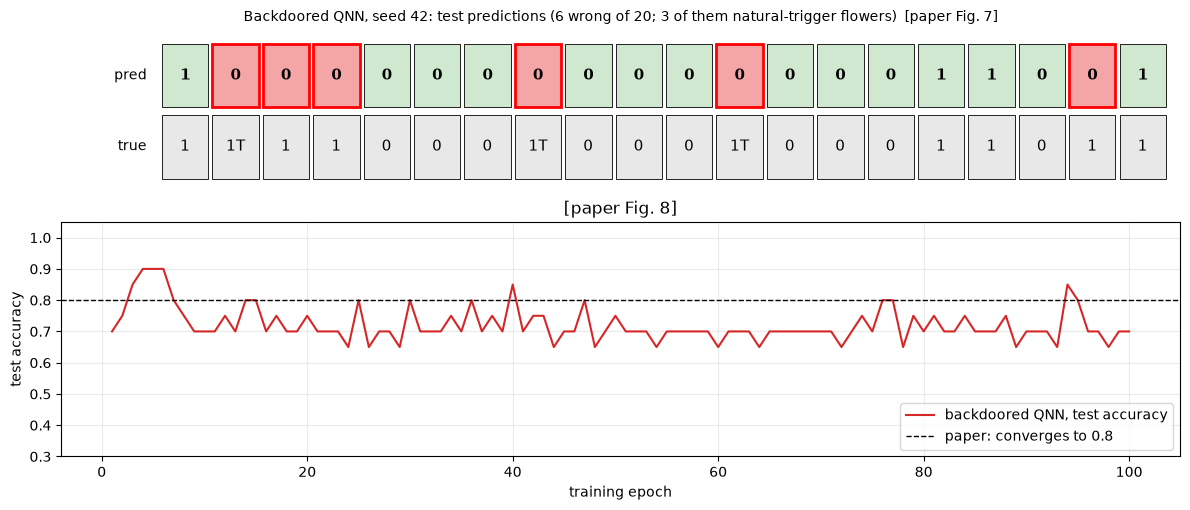

{'ACC': 0.7, 'CA': 0.824, 'ASR': 0.7, 'NAT': 1.0, 'n_wrong': 6, 'n_wrong_nat': 3, 'n_nat': 3}
training accuracy on the poisoned labels: 0.900


In [14]:
def show_predictions(ax, d, pred, title):
    n = len(d["yte"]); nat = d["Xte4"][:, 0] >= TRIGGER_THRESHOLD
    for i in range(n):
        wrong = pred[i] != d["yte"][i]
        ax.add_patch(plt.Rectangle((i, 1), 0.92, 0.9, color="#f4a6a6" if wrong else "#cfe8cf", ec="r" if wrong else "k", lw=2 if wrong else 0.6))
        ax.add_patch(plt.Rectangle((i, 0), 0.92, 0.9, color="#e8e8e8", ec="k", lw=0.6))
        ax.text(i + 0.46, 1.45, str(pred[i]), ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(i + 0.46, 0.45, str(d["yte"][i]) + ("T" if nat[i] else ""), ha="center", va="center", fontsize=11)
    ax.text(-0.3, 1.45, "pred", ha="right", va="center"); ax.text(-0.3, 0.45, "true", ha="right", va="center")
    ax.set_xlim(-2, n + 0.2); ax.set_ylim(-0.1, 2.1); ax.axis("off"); ax.set_title(title, fontsize=10)

d = R42["d"]; m = R42["m_bd"]
fig, ax = plt.subplots(2, 1, figsize=(12, 5.2), gridspec_kw={"height_ratios": [1, 1.5]})
show_predictions(ax[0], d, m["pred"], f"Backdoored QNN, seed {SEED}: test predictions ({m['n_wrong']} wrong of 20; {m['n_wrong_nat']} of them natural-trigger flowers)  [paper Fig. 7]")
ax[1].plot(range(1, len(R42["hist_bd"]) + 1), [h[0] for h in R42["hist_bd"]], color="#d62728", label="backdoored QNN, test accuracy")
ax[1].axhline(PAPER["acc_backdoor"], color="k", ls="--", lw=1, label="paper: converges to 0.8")
ax[1].set_xlabel("training epoch"); ax[1].set_ylabel("test accuracy"); ax[1].set_ylim(0.3, 1.05); ax[1].legend(loc="lower right"); ax[1].set_title("[paper Fig. 8]")
plt.tight_layout(); plt.show()
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in m.items() if k != "pred"})
print("training accuracy on the poisoned labels: %.3f" % R42["train_acc_bd"])

## 4. Detecting the backdoor samples with activation clustering (ACDM; paper Section 5.1, Fig. 9, Table 4)

Activation clustering rests on one idea: after training, the poisoned flowers are treated differently by the network than the honest flowers *of the same label*, so their activations form a separate cluster.
We read two kinds of "activation" of the trained backdoored QNN (`# CHOICE`, because the paper only says "measurement layer"):

* `probs16`: the 16 basis-state probabilities of the output state, i.e. the full measurement distribution (high-dimensional, as the paper describes it, so PCA is needed);
* `logits2`: the two read-out expectations `<Z_2>`, `<Z_3>` that the classifier compares.

**Fig. 9 / Table 4.** The paper projects the activations to 2-D with PCA, colours clean and backdoor samples differently and reports silhouette 0.81 and CH 286.35. We draw the same picture with the *ground-truth*
clean/backdoor labels (we know which flowers we poisoned) and compute both metrics for the true partition and for the K-means partition.

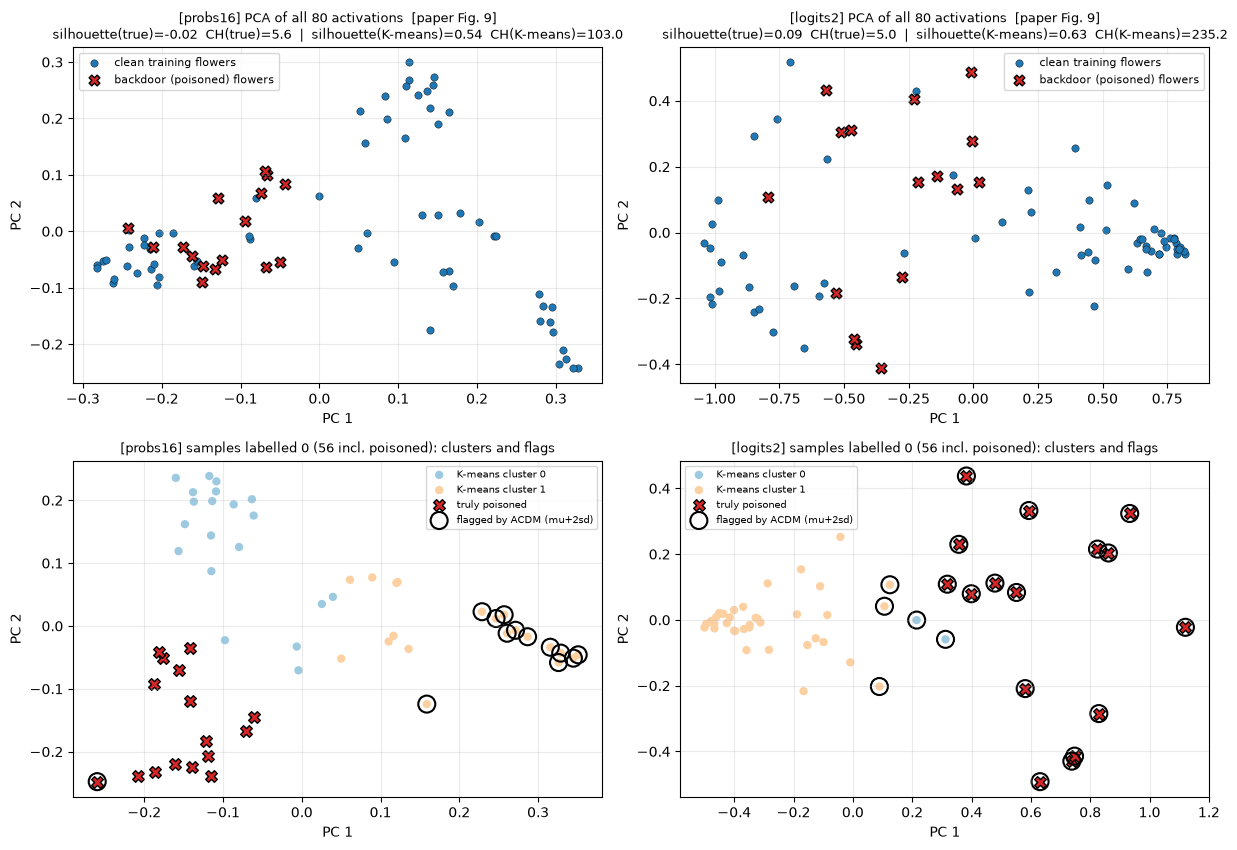

Detection against the ground truth (16 poisoned flowers in the training set), seed 42
activation     rule  flagged  tp  fp  fn  precision  recall  kept
   probs16   mu+2sd       22   1  21  15       0.05    0.06    58
   probs16 minority       30   0  30  16       0.00    0.00    50
   logits2   mu+2sd       28  16  12   0       0.57    1.00    52
   logits2 minority       25  16   9   0       0.64    1.00    55

Per-class clustering info (probs16): {0: {'n': 56, 'pca_dims': 7, 'sizes': [36, 20], 'threshold': 0.3218974561881114}, 1: {'n': 24, 'pca_dims': 8, 'sizes': [10, 14], 'threshold': 0.19624258739651076}}
Per-class clustering info (logits2): {0: {'n': 56, 'pca_dims': 2, 'sizes': [18, 38], 'threshold': 0.36842639710888925}, 1: {'n': 24, 'pca_dims': 2, 'sizes': [17, 7], 'threshold': 0.32999722764675254}}

                probs16  logits2
sil_true_pca2    -0.016    0.095
ch_true_pca2      5.588    4.988
sil_km_pca2       0.540    0.626
ch_km_pca2      103.045  235.170
ari_km_pca2    

In [15]:
def fig9(R, kinds=("probs16", "logits2")):
    d = R["d"]
    fig, ax = plt.subplots(2, len(kinds), figsize=(6.2 * len(kinds), 8.6))
    for c, kind in enumerate(kinds):
        act = R["acts"][kind]
        Z = PCA(2, random_state=R["seed"]).fit_transform(act)
        a = ax[0, c]
        a.scatter(*Z[~d["ispois"]].T, s=28, color="tab:blue", label="clean training flowers", edgecolor="k", linewidth=0.3)
        a.scatter(*Z[d["ispois"]].T, s=60, color="tab:red", marker="X", label="backdoor (poisoned) flowers", edgecolor="k")
        s = R["sep"][kind]
        a.set_title(f"[{kind}] PCA of all 80 activations  [paper Fig. 9]\nsilhouette(true)={s['sil_true_pca2']:.2f}  CH(true)={s['ch_true_pca2']:.1f}  |  silhouette(K-means)={s['sil_km_pca2']:.2f}  CH(K-means)={s['ch_km_pca2']:.1f}", fontsize=9)
        a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.legend(fontsize=8)
        # the label class that holds the poisoned flowers (class 0): K-means clusters and decision
        ii = np.where(d["ytr"] == TARGET_LABEL)[0]
        Zc = PCA(PCA_VAR, random_state=R["seed"]).fit_transform(act[ii]); Zc2 = PCA(2, random_state=R["seed"]).fit_transform(act[ii])
        km = KMeans(2, n_init=10, random_state=R["seed"]).fit_predict(Zc)
        f = R["flags"][kind]["mu+2sd"][ii]
        b = ax[1, c]
        b.scatter(*Zc2[km == 0].T, s=36, color="#9ecae1", label="K-means cluster 0", edgecolor="none")
        b.scatter(*Zc2[km == 1].T, s=36, color="#fdd0a2", label="K-means cluster 1", edgecolor="none")
        b.scatter(*Zc2[d["ispois"][ii]].T, s=70, marker="X", color="tab:red", label="truly poisoned", edgecolor="k")
        b.scatter(*Zc2[f].T, s=150, facecolors="none", edgecolors="k", linewidths=1.5, label="flagged by ACDM (mu+2sd)")
        b.set_title(f"[{kind}] samples labelled 0 (56 incl. poisoned): clusters and flags", fontsize=9)
        b.set_xlabel("PC 1"); b.set_ylabel("PC 2"); b.legend(fontsize=7)
    plt.tight_layout(); plt.show()

fig9(R42)
rows = []
for kind in R42["acts"]:
    for rule in ("mu+2sd", "minority"):
        r = R42["det"][(kind, rule)]; rows.append(dict(activation=kind, rule=rule, **{k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()}))
print("Detection against the ground truth (16 poisoned flowers in the training set), seed", SEED)
print(pd.DataFrame(rows).to_string(index=False))
print()
print("Per-class clustering info (probs16):", R42["info"]["probs16"])
print("Per-class clustering info (logits2):", R42["info"]["logits2"])
print()
print(pd.DataFrame(R42["sep"]).round(3).to_string())

## 5. Defence: retrain on the cleaned data (paper Section 5.2, Fig. 10 and Fig. 11)

The flagged flowers are removed and the same model (same start angles, same budget) is trained again; then it is tested on the same 20 flowers. The paper reports that now "the predictions align with the actual
classifications" and the accuracy curve rises (Figs. 10, 11). Below: the predictions of the defended model for both activation kinds under the paper's `mu+2sd` rule, the accuracy curves, and a table of all variants.

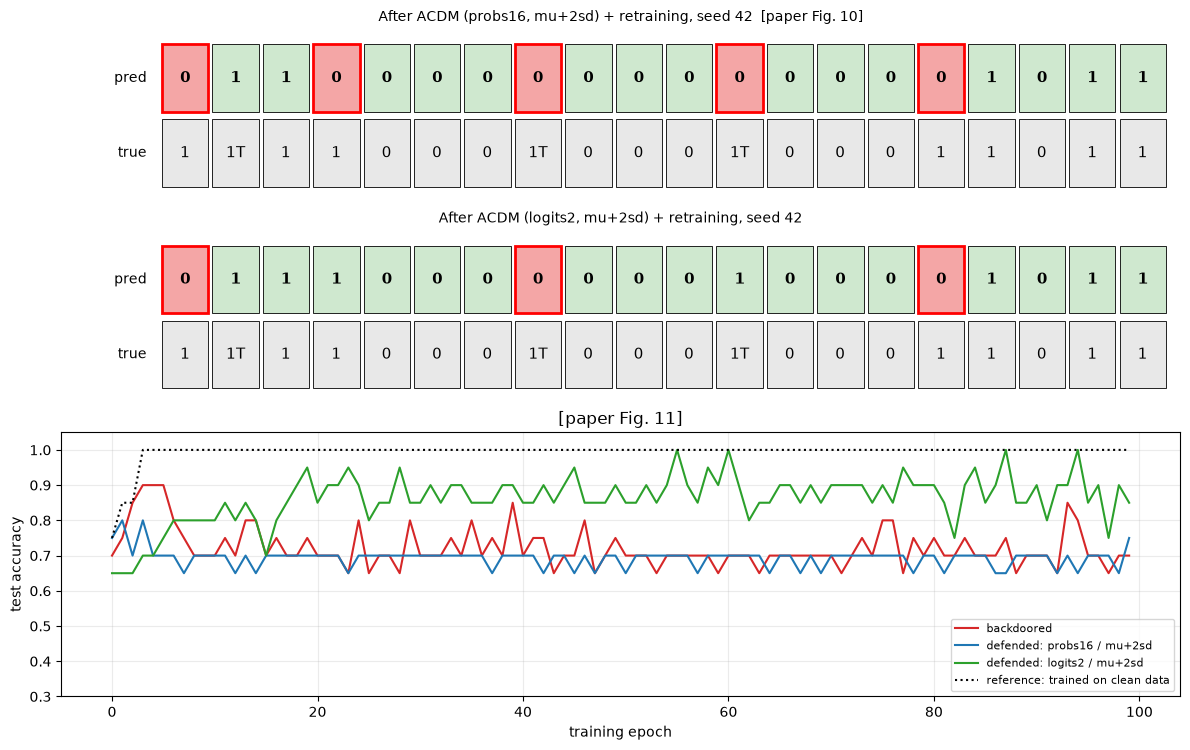

                                           model  ACC    CA  ASR   NAT  wrong
           QNN trained on CLEAN data (reference) 1.00 1.000  0.0 0.000      0
       QNN trained on POISONED data (backdoored) 0.70 0.824  0.7 1.000      6
  QNN after ACDM [probs16 / mu+2sd] + retraining 0.75 0.824  0.9 0.667      5
QNN after ACDM [probs16 / minority] + retraining 0.70 0.765  1.0 0.667      6
  QNN after ACDM [logits2 / mu+2sd] + retraining 0.85 0.882  0.8 0.333      3
QNN after ACDM [logits2 / minority] + retraining 1.00 1.000  0.5 0.000      0


In [16]:
d = R42["d"]
fig, ax = plt.subplots(3, 1, figsize=(12, 7.6), gridspec_kw={"height_ratios": [1, 1, 1.6]})
k1, k2 = (ACT_PRIMARY, "mu+2sd"), ("logits2", "mu+2sd")
show_predictions(ax[0], d, R42["m_def"][k1]["pred"], f"After ACDM ({k1[0]}, {k1[1]}) + retraining, seed {SEED}  [paper Fig. 10]")
show_predictions(ax[1], d, R42["m_def"][k2]["pred"], f"After ACDM ({k2[0]}, {k2[1]}) + retraining, seed {SEED}")
ax[2].plot([h[0] for h in R42["hist_bd"]], color="#d62728", label="backdoored")
ax[2].plot([h[0] for h in R42["hist_def"][k1]], color="#1f77b4", label=f"defended: {k1[0]} / {k1[1]}")
ax[2].plot([h[0] for h in R42["hist_def"][k2]], color="#2ca02c", label=f"defended: {k2[0]} / {k2[1]}")
ax[2].plot([h[0] for h in R42["hist_clean"]], color="k", ls=":", label="reference: trained on clean data")
ax[2].set_xlabel("training epoch"); ax[2].set_ylabel("test accuracy"); ax[2].set_ylim(0.3, 1.05); ax[2].legend(loc="lower right", fontsize=8); ax[2].set_title("[paper Fig. 11]")
plt.tight_layout(); plt.show()

def row(name, m):
    return dict(model=name, ACC=m["ACC"], CA=m["CA"], ASR=m["ASR"], NAT=m["NAT"], wrong=m["n_wrong"])
tab = [row("QNN trained on CLEAN data (reference)", R42["m_clean"]), row("QNN trained on POISONED data (backdoored)", R42["m_bd"])]
for (kind, rule), m in R42["m_def"].items():
    tab.append(row(f"QNN after ACDM [{kind} / {rule}] + retraining", m))
print(pd.DataFrame(tab).round(3).to_string(index=False))

## 6. Classical baselines on exactly the same 7 inputs

The paper compares with no classical model. A fair reading needs one: do a random forest and an RBF-SVM trained on the same poisoned 7-feature inputs also learn the backdoor, and does the ACDM cleaning
(flags from the QNN's activations) help them too? Both are scored with the same four metrics on the same 20 test flowers. "clean (no attack)" is trained on the unpoisoned training labels and shows how much of
`ASR` is just ordinary classification error for a stamped sepal length of 6.8 cm.

In [17]:
rows = []
for (kind, setting), m in R42["cl"].items():
    rows.append(dict(model=kind, training_set=setting, ACC=m["ACC"], CA=m["CA"], ASR=m["ASR"], NAT=m["NAT"], wrong=m["n_wrong"]))
rows.append(dict(model="QNN", training_set="poisoned", ACC=R42["m_bd"]["ACC"], CA=R42["m_bd"]["CA"], ASR=R42["m_bd"]["ASR"], NAT=R42["m_bd"]["NAT"], wrong=R42["m_bd"]["n_wrong"]))
mk = R42["m_def"][(ACT_PRIMARY, "mu+2sd")]
rows.append(dict(model="QNN", training_set="ACDM-cleaned (" + ACT_PRIMARY + ")", ACC=mk["ACC"], CA=mk["CA"], ASR=mk["ASR"], NAT=mk["NAT"], wrong=mk["n_wrong"]))
rows.append(dict(model="QNN", training_set="clean (no attack)", ACC=R42["m_clean"]["ACC"], CA=R42["m_clean"]["CA"], ASR=R42["m_clean"]["ASR"], NAT=R42["m_clean"]["NAT"], wrong=R42["m_clean"]["n_wrong"]))
print(pd.DataFrame(rows).sort_values(["model", "training_set"]).round(3).to_string(index=False))

model           training_set  ACC    CA  ASR   NAT  wrong
  QNN ACDM-cleaned (probs16) 0.75 0.824  0.9 0.667      5
  QNN      clean (no attack) 1.00 1.000  0.0 0.000      0
  QNN               poisoned 0.70 0.824  0.7 1.000      6
   RF           ACDM-cleaned 0.80 0.824  1.0 0.333      4
   RF      clean (no attack) 1.00 1.000  0.0 0.000      0
   RF               poisoned 0.85 0.882  1.0 0.333      3
  SVC           ACDM-cleaned 0.75 0.882  1.0 1.000      5
  SVC      clean (no attack) 1.00 1.000  0.0 0.000      0
  SVC               poisoned 0.75 0.882  1.0 1.000      5


## 7. Five repetitions (paper Section 4.2: "repeated five times, mean +- standard deviation")

Each repetition uses a different seed (`SEED`, `SEED + 1`, ...) and therefore a different train/test split, a different choice of the 16 poisoned flowers and different start angles. Everything else is identical.

In [18]:
RUNS = [R42] + [run_experiment(SEED + i) for i in range(1, N_RUNS)]
print("runs:", [r["seed"] for r in RUNS], "| total time %.0f s" % sum(r["time"] for r in RUNS))

def agg(getter, keys=("ACC", "CA", "ASR", "NAT")):
    out = {}
    for k in keys:
        v = np.array([getter(r)[k] for r in RUNS], float)
        out[k] = f"{np.nanmean(v):.2f} +- {np.nanstd(v):.2f}" if np.isfinite(v).any() else "n/a"
    return out

rows = [dict(model="QNN trained on clean data (reference)", **agg(lambda r: r["m_clean"])),
        dict(model="QNN trained on poisoned data (backdoored)", **agg(lambda r: r["m_bd"]))]
for key in RUNS[0]["m_def"]:
    rows.append(dict(model=f"QNN + ACDM [{key[0]} / {key[1]}] + retraining", **agg(lambda r, key=key: r["m_def"][key])))
for kind in ("RF", "SVC"):
    for setting in ("clean (no attack)", "poisoned", "ACDM-cleaned"):
        rows.append(dict(model=f"{kind} {setting}", **agg(lambda r, kind=kind, setting=setting: r["cl"][(kind, setting)])))
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

det_rows = []
for key in RUNS[0]["det"]:
    g = lambda f: np.array([r["det"][key][f] for r in RUNS], float)
    det_rows.append(dict(activation=key[0], rule=key[1], flagged=f"{g('flagged').mean():.1f}", true_pos=f"{g('tp').mean():.1f} / 16", false_pos=f"{g('fp').mean():.1f}",
                         precision=f"{g('precision').mean():.2f} +- {g('precision').std():.2f}", recall=f"{g('recall').mean():.2f} +- {g('recall').std():.2f}", kept_for_retraining=f"{g('kept').mean():.1f} of 80"))
print()
print("ACDM detection quality (poisoned flowers are known to us, not to the defender):")
print(pd.DataFrame(det_rows).to_string(index=False))

seed 43: done in 162 s | backdoored QNN ACC=1.00 ASR=0.70 | defended (probs16, mu+2sd) ACC=1.00 ASR=0.00


seed 44: done in 228 s | backdoored QNN ACC=0.85 ASR=0.90 | defended (probs16, mu+2sd) ACC=0.95 ASR=0.80


seed 45: done in 240 s | backdoored QNN ACC=0.75 ASR=0.80 | defended (probs16, mu+2sd) ACC=0.90 ASR=0.10


seed 46: done in 242 s | backdoored QNN ACC=0.95 ASR=0.40 | defended (probs16, mu+2sd) ACC=0.80 ASR=0.40
runs: [42, 43, 44, 45, 46] | total time 1092 s
                                       model          ACC           CA          ASR          NAT
       QNN trained on clean data (reference) 0.97 +- 0.06 0.98 +- 0.04 0.16 +- 0.32 0.25 +- 0.43
   QNN trained on poisoned data (backdoored) 0.85 +- 0.11 0.89 +- 0.08 0.70 +- 0.17 0.75 +- 0.43
  QNN + ACDM [probs16 / mu+2sd] + retraining 0.88 +- 0.09 0.90 +- 0.09 0.44 +- 0.36 0.42 +- 0.43
QNN + ACDM [probs16 / minority] + retraining 0.90 +- 0.11 0.92 +- 0.09 0.54 +- 0.37 0.42 +- 0.43
  QNN + ACDM [logits2 / mu+2sd] + retraining 0.93 +- 0.09 0.94 +- 0.07 0.34 +- 0.42 0.33 +- 0.41
QNN + ACDM [logits2 / minority] + retraining 0.93 +- 0.09 0.95 +- 0.07 0.48 +- 0.31 0.50 +- 0.50
                        RF clean (no attack) 1.00 +- 0.00 1.00 +- 0.00 0.00 +- 0.00 0.00 +- 0.00
                                 RF poisoned 0.95 +- 0.05 0.98 +- 0.05 0

 seed  backdoored_ACC  backdoored_ASR  backdoored_NAT  wrong  wrong_natural_trigger  defended_ACC  defended_ASR  defended_logits2_ACC  defended_logits2_ASR  clean_ref_ACC  clean_ref_ASR
   42            0.70             0.7             1.0      6                      3          0.75           0.9                  0.85                   0.8           1.00            0.0
   43            1.00             0.7             NaN      0                      0          1.00           0.0                  1.00                   0.0           1.00            0.0
   44            0.85             0.9             1.0      3                      1          0.95           0.8                  0.80                   0.9           0.85            0.8
   45            0.75             0.8             1.0      5                      1          0.90           0.1                  1.00                   0.0           1.00            0.0
   46            0.95             0.4             0.0      1          

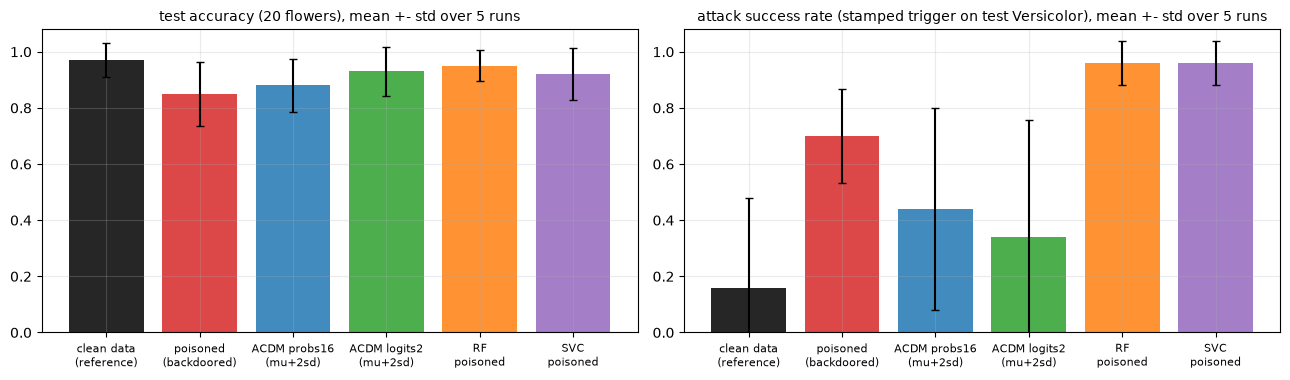

In [19]:
# per-run table and bar chart (mean +- std over the repetitions)
per_run = pd.DataFrame([dict(seed=r["seed"], backdoored_ACC=r["m_bd"]["ACC"], backdoored_ASR=r["m_bd"]["ASR"], backdoored_NAT=r["m_bd"]["NAT"], wrong=r["m_bd"]["n_wrong"], wrong_natural_trigger=r["m_bd"]["n_wrong_nat"],
                             defended_ACC=r["m_def"][(ACT_PRIMARY, "mu+2sd")]["ACC"], defended_ASR=r["m_def"][(ACT_PRIMARY, "mu+2sd")]["ASR"],
                             defended_logits2_ACC=r["m_def"][("logits2", "mu+2sd")]["ACC"], defended_logits2_ASR=r["m_def"][("logits2", "mu+2sd")]["ASR"],
                             clean_ref_ACC=r["m_clean"]["ACC"], clean_ref_ASR=r["m_clean"]["ASR"]) for r in RUNS])
print(per_run.round(2).to_string(index=False))

labels = ["clean data\n(reference)", "poisoned\n(backdoored)", f"ACDM {ACT_PRIMARY}\n(mu+2sd)", "ACDM logits2\n(mu+2sd)", "RF\npoisoned", "SVC\npoisoned"]
getters = [lambda r: r["m_clean"], lambda r: r["m_bd"], lambda r: r["m_def"][(ACT_PRIMARY, "mu+2sd")], lambda r: r["m_def"][("logits2", "mu+2sd")],
           lambda r: r["cl"][("RF", "poisoned")], lambda r: r["cl"][("SVC", "poisoned")]]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
for a, met, ttl in ((ax[0], "ACC", "test accuracy (20 flowers)"), (ax[1], "ASR", "attack success rate (stamped trigger on test Versicolor)")):
    mu = [np.mean([g(r)[met] for r in RUNS]) for g in getters]; sd = [np.std([g(r)[met] for r in RUNS]) for g in getters]
    a.bar(range(len(labels)), mu, yerr=sd, color=["k", "#d62728", "#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"], capsize=3, alpha=0.85)
    a.set_xticks(range(len(labels))); a.set_xticklabels(labels, fontsize=8); a.set_title(f"{ttl}, mean +- std over {len(RUNS)} runs", fontsize=10); a.set_ylim(0, 1.08)
plt.tight_layout(); plt.show()

## 8. Side by side with the paper

Verdict rules (fixed before looking at the numbers): a value is **reproduced** if it lies within the stated tolerance of the paper's value, **exceeded** / **not reached** if it is better / worse than the tolerance band,
and **cannot be checked** if the paper gives no number. Tolerances: one test flower (0.05) for accuracies, because the paper's single 20-flower test set cannot resolve less; 0.05 for the silhouette coefficient; 25 % relative for the CH index;
exact equality for counts. Rows marked *(variant)* use the other reading of "activation" and are reported for transparency.

In [20]:
def verdict(paper, got, tol, rel=False, higher_better=True, two_sided=False):
    # two_sided: the paper value is a target to hit (e.g. "converges to 0.8"), so any miss is "not reached" and the direction is stated
    if got is None or not np.isfinite(got): return "cannot be checked"
    gap = got - paper; lim = tol * abs(paper) if rel else tol
    if abs(gap) <= lim: return "reproduced"
    if two_sided: return "not reached (higher than paper)" if gap > 0 else "not reached (lower than paper)"
    return ("exceeded" if gap > 0 else "not reached") if higher_better else ("not reached" if gap > 0 else "exceeded")

ms = lambda f: (np.nanmean([f(r) for r in RUNS]), np.nanstd([f(r) for r in RUNS]))
fmt = lambda t, p=2: f"{t[0]:.{p}f} +- {t[1]:.{p}f}"
rows = []
def add(claim, paper_txt, got_txt, v):
    rows.append({"claim": claim, "paper": paper_txt, "this notebook": got_txt, "verdict": v})

add("Iris class means (Table 2) match the data used", "see Table 2", f"max deviation {max_dev:.4f} cm", "reproduced" if max_dev < 1e-3 else "not reached")
add("Gate / parameter counts (encoder, trainable, total)", "17/7, 25/16, 42/23", "%d/%d, %d/%d, %d/%d" % (*count(enc_ops), *count(trn_ops), *count(tot_ops)),
    "reproduced" if (count(enc_ops), count(trn_ops), count(tot_ops)) == ((17, 7), (25, 16), (42, 23)) else "not reached")
a = ms(lambda r: r["m_bd"]["ACC"])
add("Backdoored QNN test accuracy converges to ~0.8 (Fig. 8)", "0.80", f"{fmt(a)} (seed {SEED}: {R42['m_bd']['ACC']:.2f})", verdict(0.80, a[0], 0.05, two_sided=True))
w_ = ms(lambda r: r["m_bd"]["n_wrong"])
add("Number of wrong test flowers of the backdoored QNN (Fig. 7)", "4 of 20", f"{fmt(w_, 1)} of 20", verdict(4, w_[0], 1.0, two_sided=True))
tot_w, tot_n = sum(r["m_bd"]["n_wrong"] for r in RUNS), sum(r["m_bd"]["n_wrong_nat"] for r in RUNS)
frac = tot_n / max(tot_w, 1)
add("The wrong flowers are Versicolor with sepal length >= 6.5 predicted as 0", "all of them", f"{tot_n} of {tot_w} errors over {len(RUNS)} runs ({frac:.0%})", verdict(1.0, frac, 0.10, two_sided=True))
nat = ms(lambda r: r["m_bd"]["NAT"])
add("Test flowers carrying the natural trigger are sent to class 0", "4 of 4", f"{fmt(nat)} (fraction, runs with such flowers)", verdict(1.0, nat[0], 0.05))
asr = ms(lambda r: r["m_bd"]["ASR"])
add("Stamped trigger success rate (not reported by the paper)", "not reported", f"ASR {fmt(asr)} vs clean model {fmt(ms(lambda r: r['m_clean']['ASR']))}", "cannot be checked")
for kind, tag in ((ACT_PRIMARY, ""), ("logits2" if ACT_PRIMARY != "logits2" else "probs16", " (variant)")):
    s = ms(lambda r: r["sep"][kind]["sil_true_pca2"]); c = ms(lambda r: r["sep"][kind]["ch_true_pca2"])
    add(f"Silhouette of clean vs backdoor activations, 2-D PCA, true partition [{kind}]{tag}", "0.81", fmt(s), verdict(0.81, s[0], 0.05))
    add(f"CH index of clean vs backdoor activations, 2-D PCA, true partition [{kind}]{tag}", "286.35", fmt(c, 1), verdict(286.35, c[0], 0.25, rel=True))
    s2 = ms(lambda r: r["sep"][kind]["sil_km_pca2"]); c2 = ms(lambda r: r["sep"][kind]["ch_km_pca2"]); ari = ms(lambda r: r["sep"][kind]["ari_km_pca2"])
    add(f"Silhouette of the K-means (K=2) partition, 2-D PCA [{kind}]{tag}", "0.81", fmt(s2), verdict(0.81, s2[0], 0.05))
    add(f"CH index of the K-means (K=2) partition, 2-D PCA [{kind}]{tag}", "286.35", fmt(c2, 1), verdict(286.35, c2[0], 0.25, rel=True))
    add(f"K-means clusters coincide with clean/backdoor (adjusted Rand index) [{kind}]{tag}", "~1 (clusters 'almost no overlap')", fmt(ari), verdict(1.0, ari[0], 0.10))
dims = ms(lambda r: r["info"][ACT_PRIMARY][0]["pca_dims"])
add("PCA keeps > 95 % of the variance (components per class, probs16)", "> 95 %", f"{dims[0]:.1f} components (by construction)", "reproduced")
for kind in (ACT_PRIMARY, "logits2"):
    key = (kind, "mu+2sd"); e = ms(lambda r: r["m_def"][key]["ACC"]); s_ = ms(lambda r: r["m_def"][key]["ASR"]); cr = ms(lambda r: r["m_clean"]["ASR"])
    tag = "" if kind == ACT_PRIMARY else " (variant)"
    add(f"Test accuracy after ACDM + retraining, predictions 'align' (Fig. 10/11) [{kind}]{tag}", "~1.00 (all 20 correct)", f"{fmt(e)} (seed {SEED}: {R42['m_def'][key]['ACC']:.2f})", verdict(1.00, e[0], 0.05))
    add(f"Backdoor effect removed: ASR after defence vs clean-model ASR [{kind}]{tag}", "implied: no longer misclassified", f"{fmt(s_)} vs {fmt(cr)} (backdoored {fmt(asr)})", verdict(cr[0], s_[0], 0.10, higher_better=False))
    p = ms(lambda r: r["det"][key]["precision"]); rc = ms(lambda r: r["det"][key]["recall"])
    add(f"Detection precision / recall of the flagged flowers [{kind}]{tag}", "not reported", f"precision {fmt(p)}, recall {fmt(rc)}", "cannot be checked")
comp = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
print(comp.to_string(index=False))
print()
print(comp["verdict"].value_counts().to_string())

                                                                                      claim                             paper                                          this notebook                        verdict
                                             Iris class means (Table 2) match the data used                       see Table 2                                max deviation 0.0000 cm                     reproduced
                                        Gate / parameter counts (encoder, trainable, total)                17/7, 25/16, 42/23                                     17/7, 25/16, 42/23                     reproduced
                                    Backdoored QNN test accuracy converges to ~0.8 (Fig. 8)                              0.80                           0.85 +- 0.11 (seed 42: 0.70)                     reproduced
                                Number of wrong test flowers of the backdoored QNN (Fig. 7)                           4 of 20                           

## 9. Reading the paper critically

What the executed run (`FAST_MODE = False`, 100 epochs, five seeds; numbers quoted below are from the tables above) lets us say, and what it does not.

1. **The evidence in the paper is one run on 20 test flowers.** One wrong flower is 5 accuracy points, and the paper gives no table, no standard deviations (although it says five repetitions were made), no detection precision/recall, and no clean-model
   baseline. Over our five seeds the backdoored QNN has test accuracy 0.85 +- 0.11 (range 0.70 to 1.00): the "about 0.8" is inside that spread, but so are values (1.00, seed 43) at which the backdoor is invisible on the natural test set although
   the stamped trigger still flips 70 % of the Versicolor flowers.
2. **The backdoor is not fully specified.** The trigger "sepal length >= 6.5 cm" is a *region of the real feature space*, not a pattern added by the attacker: Setosa flowers never reach it, so only Versicolor flowers can be poisoned in a meaningful way, and
   the paper does not say how the 16 poisoned flowers were made. With our reading (random Versicolor flowers, sepal length := 6.8, label := 0) the number of naturally triggered test flowers varies from 0 to 3 across seeds, and only
   5 of the 15 test errors of the backdoored models were natural-trigger flowers (the paper: all four). The QNN also errs on ordinary flowers, because a 4-qubit, 16-parameter circuit trained on a noisy, partly contradictory training set is a weak classifier. Even
   the clean-trained QNN has a stamped-trigger "ASR" of 0.16 +- 0.32 (one seed is bad), so ASR must always be read against that reference.
3. **Table 4 and Fig. 9 are not reproduced and are weak evidence.** For the true clean/backdoor partition the silhouette is about 0.0 to 0.1 and the CH index about 7 (paper: 0.81 and 286.35): the poisoned flowers are Versicolor flowers labelled 0 and the
   trained model gives them activations that lie *between* and *on top of* the honest Setosa activations (Fig. 9 above). Global K-means does find two compact blobs (silhouette 0.56 for `probs16`, 0.69 for `logits2`), but those blobs are essentially the
   two species (adjusted Rand index with the poison labels 0.07 and 0.14), so a high silhouette says nothing about backdoors. The CH index of the K-means partition for `logits2` (320 +- 64) happens to fall inside the 25 % band around 286.35; with an ARI of 0.14 that is a
   coincidence, not a reproduction, and we do not count it as one.
4. **Detection works only in one reading, and then with many false alarms.** Run *inside each label class*, as classical activation clustering does, K-means on the two read-out expectations (`logits2`) isolates **all 16** poisoned flowers in all five runs (recall 1.00)
   but also removes about 10 honest flowers (precision 0.61); on the 16 basis-state probabilities the poisoned flowers are not a cluster of their own (recall 0.45, precision 0.24). The paper says "measurement probabilities", i.e. the
   high-dimensional reading, and that reading fails here. The decision rule matters as well (a cluster-size rule would flag the wrong cluster for `probs16`).
5. **Retraining does not reliably "align" the predictions.** After cleaning, test accuracy is 0.88 +- 0.09 (`probs16`) or 0.93 +- 0.09 (`logits2`) against the paper's all-correct Fig. 10, and the stamped-trigger success rate drops from 0.70 to 0.44 or 0.34 but not to the clean level
   of 0.16. Deleting 10 to 17 honest flowers from an 80-flower training set is itself a perturbation of the model; the paper has no control that removes the same number of *random* flowers (Exercise 3).
6. **Nothing here is specifically quantum.** ACDM is classical activation clustering applied to the output layer of a QNN. The paper argues that classical defences cannot be applied to QNNs, but it never runs one for comparison. Our baselines show the opposite
   direction: a random forest and an RBF-SVM learn the same backdoor even more reliably (stamped-trigger success 0.96 +- 0.08), and the very same flags computed from the QNN's activations halve it (0.56 +- 0.46). The claims about covert triggers, images and deep QNNs are speculation: none was tested.
7. **What did reproduce.** The data (Table 2 means to three decimals), the circuit (17/7, 25/16, 42/23 gates/parameters, depth 21), and, on average, the headline numbers of the poisoned model (about 0.85 accuracy, three of twenty test flowers wrong). The attack itself is real: with 20 % poisoned flowers a QNN, a random forest and an SVM all send most
   triggered Versicolor flowers to class 0.
8. **Caveats of this reproduction.** The circuit wiring is reconstructed from gate counts, the optimiser, batch size and start angles are our choices, the NumPy twin replaces the PennyLane QNode for training (asserted equal to 1e-10), and the poisoning procedure is our reading of a vague description. Different choices could move every number
   above; the *qualitative* findings (poor clean/backdoor separation of the full probability vector, no more than partial removal of the backdoor, sensitivity to the decision rule) were stable across our seeds.

## 10. Exercises

1. **Poison rate.** Run `run_experiment(SEED, verbose=False)` after changing `POISON_RATE` to 0.05, 0.10 and 0.30 (`make_data` reads the global at call time). Plot `ASR` and `ACC` of the backdoored QNN against the poison rate. At what rate does the backdoor start to work, and does ACDM's recall change?
2. **Other activations.** Add a third activation kind to `activations()`: the real and imaginary parts of the 16 amplitudes of the output state (32 numbers), or the activations of an intermediate layer (apply only the first two RY/CNOT blocks). Which choice separates the 16 poisoned flowers best in the per-class clustering? Why might the 2 read-out numbers behave so differently from the 16 probabilities?
3. **Better decision rule and a control.** The `mu+2sd` rule flags many honest flowers. Replace it by (a) Chen et al.'s relative-size criterion (a cluster below 35 % of its class is poisoned), (b) a silhouette test that only flags a class when its two clusters are well separated, or (c) a Gaussian mixture model. Measure precision, recall and the number of kept flowers over five seeds. Add the missing control: retrain after removing the *same number of random* flowers and compare the resulting ASR and ACC with ACDM's.
4. **A smarter attacker.** Replace the trigger "sepal length >= 6.5" by a trigger that is hard to see in the activations: stamp it on flowers *of the target class* (a clean-label attack), or use a combination such as "petal width >= 1.4 and sepal width <= 2.8". Does ACDM still find the poisoned flowers? What does the random forest do?
5. **Circuit capacity.** Change `DEPTH` to 1, 2 and 4, or replace the linear CNOT chain by a ring. Track the training accuracy on the poisoned labels (`train_acc_bd`) next to `ASR`. Does a larger circuit memorise the backdoor more reliably, and does that make the defence easier or harder?